*openmobisim tutorials* · [00 · overview](00_getting_started.ipynb) · ← [08 · Performance](08_performance.ipynb) · [documentation](https://openmobisim.github.io)

# 09 · Five minimal studies

What the simulator is for: studies. This notebook runs five of them, each small but honest, on one starter case —
Amsterdam's morning — and says for each what it leaves out. They are starting points to copy and extend, not results
about Amsterdam.

1. **Transit frequency**: every bus, tram and metro line twice as often in the morning peak — the scenario sections
   2 to 4 also compare with the base.
2. **Your own utility**: a choice model written in Python, with a term the built-in models cannot express.
3. **Accessibility**: the logsum (what the choice set is worth to each traveller) and travel-time matrices.
4. **Emissions**: CO₂ and NOₓ of the cars from their kilometres and speeds, with the European guidebook's factors.
5. **Disruptions**: the road link the most people depend on, closed for an hour, travellers warned or not.

**Terms used here.**
- The **base run** is the case as it comes; a **scenario** changes one thing, and its effect is the difference from
  the base. Both use the same travellers and the same random draws (**common random numbers**), so a difference comes
  from the change, not from chance.
- A **starter case** is a network with what runs on it — a timetable, parkings, a demand and its traveller classes —
  prepared, checked and versioned (`examples.case`). Amsterdam's demand is a **synthetic morning** (06:30–09:30,
  about 496 000 people, five to each simulated traveller; the runs here take the departures from 07:30 to 08:30), made from open data and travel surveys to look like a
  morning, not to forecast one (notebook 02).
- A **traveller class** groups travellers who may use the same modes, own the same vehicles and weigh alternatives
  the same way (notebook 04). Amsterdam's are the package's example classes (`examples.traveller_classes()`): four,
  by what people own — a car and a bike, a bike only, a car only, neither — each free to use every mode its vehicles
  allow, all weighing alike, with illustrative constants; and three for what enters from outside the city and does not
  choose here (cars, transit riders, goods vehicles: notebook 02).

The case's morning simulates one traveller for every five people (its `weight`): the **fast run**, close to the
complete one for most purposes and a few times faster. Every study below uses it; **the last section runs the
complete morning once**, one simulated traveller per person, to compare.

**Start small: Delft.** Every study here also runs on Delft, the smallest starter city, in seconds a run: name
`"delft"` instead of `"amsterdam"` in the next cell and run the notebook again. Its base, for a first look:

**Download** {download}`this notebook <../_static/notebooks/09_applications.ipynb>` or {download}`all ten <../_static/notebooks/openmobisim_notebooks.zip>` (a zip), without their outputs. The Installation section below installs openmobisim; its last command, `openmobisim notebooks`, copies the same ten into a folder and opens the first in JupyterLab.

---

## Installation

> Skip this if `import openmobisim` already works in this notebook. **One install is all there is:**
> `pip install "openmobisim[all]"` brings the simulator and everything the ten tutorials use (JupyterLab,
> matplotlib for the figures, pandas, polars and pyarrow for the tables); nothing is installed later. Find the case
> that matches yours and copy its commands, in order. Each needs Python 3.11 or newer.
>
> **A new conda environment** (any system; openmobisim is on PyPI, so pip installs it into the environment):
>
> ```bash
> conda create -y -n openmobisim python=3.12
> conda activate openmobisim
> pip install "openmobisim[all]"
> openmobisim notebooks
> ```
>
> **A new venv on macOS or Linux** (in a terminal):
>
> ```bash
> python3 -m venv openmobisim
> source openmobisim/bin/activate
> pip install "openmobisim[all]"
> openmobisim notebooks
> ```
>
> **A new venv on Windows** (in the Command Prompt):
>
> ```bat
> py -m venv openmobisim
> openmobisim\Scripts\activate
> pip install "openmobisim[all]"
> openmobisim notebooks
> ```
>
> The last line copies these ten notebooks into `./openmobisim-notebooks` and opens them in JupyterLab. In VS Code or
> PyCharm, open a notebook and choose the `openmobisim` environment's Python as its kernel instead.
>
> **Into the environment this notebook already runs in**: paste this into a new code cell, run it, then restart the
> kernel.
>
> ```python
> %pip install "openmobisim[all]"
> ```

---

In [1]:
import collections

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import openmobisim as ms
from openmobisim import choice, viz

# Delft's whole morning: every departure (06:30-09:30), run on to 10:30 so the late ones arrive.
delft = ms.examples.case("delft").scenario("base", departures="all", window=("06:30", "10:30")).run(
    "delft-base", output_dir="runs/delft-base", quiet=True
)
print(f"Delft's morning: {delft.completion['total_trips']} travellers simulated, {delft.timings()['seconds'][-1]:.1f} s")

Delft's morning: 113709 travellers simulated, 18.4 s


/var/folders/q0/vjghqqvj4dvcq_z2rjmvd0jmw3f5y2/T/ipykernel_63642/529690737.py:11: NoAlternativeWarning: 3 trips (3 people, 0.0% of run 'delft-base') had no alternative — no mode they may use reached their destination within the limits — and were not simulated. By class (stated mode): 2 'no_vehicle' (choosing), 1 'from_outside_transit' (transit). Why, by mode offered (trips): walk: walk_too_long 2; transit: no_stop_in_reach 3. Most between (latitude, longitude, about 1 km): 1 people from (51.98, 4.38) to (51.98, 4.40); 1 people from (51.98, 4.40) to (51.98, 4.37); 1 people from (52.01, 4.36) to (51.97, 4.39). To change: walk_too_long: mode_options['walk_max_s'] or the class's walk_max_s; no_stop_in_reach: transit_options['access_walk_max_s'] or the class's access_walk_max_s. Run.report_no_alternative() lists every trip with its reasons.
  delft = ms.examples.case("delft").scenario("base", departures="all", window=("06:30", "10:30")).run(


In [2]:
case = ms.examples.case("amsterdam")  # found in the cache, or downloaded once and checked
net = case.network()
transit = case.transit(net)
parkings = case.parkings()
classes = case.classes()  # the example classes, and those of what enters from outside (above)
trips = case.demand()  # the fast run: five people a simulated traveller
print(case.info["title"], net, transit, parkings, f"{len(trips)} trips simulated", sep="\n")

Amsterdam
Network(115389 nodes, 252184 links, with street geometry)
Transit(2026-10-09: 7221 runs, 1868 stops, 171 lines)
Parkings(18 car, 1134 bike)
57381 trips simulated


Every run below goes through one function, so each scenario differs from the base only in what it is given. Each run
records **link bins** (`link_bin_s=900`): per road, bike and walk link and per 15 minutes, the traffic that left the
link and the time it took — what sections 4 and 5 read.

In [3]:
MODES = {
    "walk": "walk", "bike": "bike", "car": "car", "transit": "transit",
    "car_transit": "park-and-ride", "bike_transit": "bike-and-ride", None: "no alternative",
}  # fmt: skip
runs = {}


def simulate(name, network=net, timetable=transit, traveller_classes=classes, **options):
    settings = case.info["scenarios"]["base"] | options  # the case's: link bins, shared searches, a good gap
    run = ms.Scenario.from_parts(
        network, trips, classes=traveller_classes, transit=timetable, parkings=parkings, **settings,
    ).run(name, output_dir=f"runs/{name}", quiet=True)  # fmt: skip
    runs[name] = run
    return run


def row(run):
    """One scenario's line in the tables: mode shares by people, the mean trip and the run time."""
    modes = run.trip_modes()
    people = collections.Counter()
    for mode, weight in zip(modes["mode"], modes["weight"]):
        people[MODES[mode]] += weight
    total = sum(people.values())
    return {f"{label} (%)": 100 * people[label] / total for label in MODES.values()} | {
        "mean trip (min)": run.mean_travel_time_s / 60,
        "run time (s)": run.timings()["seconds"][-1],
    }


def table(*names):
    return pd.DataFrame([row(runs[n]) for n in names], index=pd.Index(names, name="run")).round(2)


base = simulate("base")
table("base")

/var/folders/q0/vjghqqvj4dvcq_z2rjmvd0jmw3f5y2/T/ipykernel_63642/2287325879.py:12: NoAlternativeWarning: 311 trips (1,555 people, 0.5% of run 'base') had no alternative — no mode they may use reached their destination within the limits — and were not simulated. By class (stated mode): 277 'no_vehicle' (choosing), 33 'from_outside_transit' (transit), 1 'car_and_bike' (choosing). Why, by mode offered (trips): car: no_road_route 1; bike: ride_too_long 1; walk: walk_too_long 278; transit: no_stop_in_reach 206, no_transit_journey 105; car_transit: too_short 1; bike_transit: too_short 1. Most between (latitude, longitude, about 1 km): 25 people from (52.39, 4.84) to (52.41, 4.85); 15 people from (52.38, 4.90) to (52.40, 4.87); 15 people from (52.40, 4.91) to (52.41, 4.85); 15 people from (52.41, 4.81) to (52.42, 4.82); 10 people from (52.35, 4.81) to (52.40, 4.87). To change: walk_too_long: mode_options['walk_max_s'] or the class's walk_max_s; ride_too_long: mode_options['bike_max_s'] or the

,walk (%),bike (%),car (%),transit (%),park-and-ride (%),bike-and-ride (%),no alternative (%),mean trip (min),run time (s)
run,,,,,,,,,
base,2.13,33.77,35.31,27.81,0.13,0.37,0.48,25.44,35.26


## 1 · Transit frequency

`transit_edit` returns a changed copy of the timetable: a line cancelled, or run at another **headway** (the time
between two departures) within a window. The study: **every bus, tram and metro line twice as often from 07:00 to
09:00**, its headway halved; the trains and ferries as they are. Each line's headway in the base is counted from its
runs that start within the window (`Run.transit_calls`, every run's calls at the stops).

In [4]:
calls = base.transit_calls()
first, line_of = {}, {}
for run, name, kind, departs in zip(calls["run"], calls["line"], calls["kind"], calls["scheduled_departure_s"]):
    if run not in first or departs < first[run]:
        first[run] = departs  # the run's first call in the study area
    line_of[run] = (name, kind)
in_peak = collections.Counter(line_of[r] for r, s in first.items() if 7 * 3600 <= s < 9 * 3600)
lines = transit.lines()
route_ids = collections.defaultdict(list)
for route_id, name, kind in zip(lines["route_id"], lines["name"], lines["kind"]):
    route_ids[(name, kind)].append(route_id)
headways, rows = {}, []
for (name, kind), runs_in_peak in in_peak.items():
    if kind in ("bus", "tram", "metro") and runs_in_peak >= 2 and len(route_ids[(name, kind)]) == 1:
        now = 2 * 7200 / runs_in_peak  # seconds between departures: two directions over two hours
        headways[route_ids[(name, kind)][0]] = (max(60, round(now / 2)), 7 * 3600, 9 * 3600)
        rows.append({"kind": kind, "headway, base (min)": now / 60, "twice as often (min)": now / 120})
double = ms.transit_edit(transit, headway=headways)
pd.DataFrame(rows).groupby("kind").agg(
    lines=("kind", "size"), **{c: (c, "mean") for c in ("headway, base (min)", "twice as often (min)")}
).round(1)

,lines,"headway, base (min)",twice as often (min)
kind,,,
bus,88,23.6,11.8
metro,4,10.5,5.3
tram,15,10.1,5.0


The table gives the lines changed and their mean headways. Then the run, and what it changes for the people who rode
transit in the base: every run has the same travellers, so each trip compares with itself (`Run.trip_results`, one row
per trip, in the same order in every run).

In [5]:
more = simulate("transit twice as often", timetable=double)
before, after = base.trip_results().to_pandas(), more.trip_results().to_pandas()
rode = (before["mode"] == "transit") & (before["outcome"] == "completed") & (after["outcome"] == "completed")


def mean_min(trips_table, rows):
    """The people-weighted mean trip, in minutes, of the given rows that completed."""
    t = trips_table.loc[rows]
    t = t[t["outcome"] == "completed"]
    return (t["travel_time_s"] * t["weight"]).sum() / t["weight"].sum() / 60


def transit_row(run, trips_table):
    m = run.completion_by_mode["transit"]
    return {
        "people taking transit": m["people"],
        "boardings": run.transit_summary["boardings"],
        "mean transit trip (min)": m["total_travel_time_s"] / m["completed_people"] / 60,
        "the base's transit riders: mean trip (min)": mean_min(trips_table, rode),
    }


saved = (before["travel_time_s"] - after["travel_time_s"])[rode] / 60
weight = before["weight"][rode]
print(f"the base's transit riders saving 5 minutes or more: {100 * weight[saved >= 5].sum() / weight.sum():.0f} %, "
      f"10 minutes or more: {100 * weight[saved >= 10].sum() / weight.sum():.0f} %")
pd.DataFrame(
    [transit_row(base, before), transit_row(more, after)], index=pd.Index(["base", "transit twice as often"], name="run")
).round(1)

the base's transit riders saving 5 minutes or more: 25 %, 10 minutes or more: 7 %


/var/folders/q0/vjghqqvj4dvcq_z2rjmvd0jmw3f5y2/T/ipykernel_63642/2287325879.py:12: NoAlternativeWarning: 280 trips (1,400 people, 0.5% of run 'transit twice as often') had no alternative — no mode they may use reached their destination within the limits — and were not simulated. By class (stated mode): 246 'no_vehicle' (choosing), 32 'from_outside_transit' (transit), 1 'bike_only' (choosing), 1 'car_and_bike' (choosing). Why, by mode offered (trips): car: no_road_route 1; bike: ride_too_long 2; walk: walk_too_long 248; transit: no_stop_in_reach 206, no_transit_journey 74; car_transit: too_short 1; bike_transit: too_short 2. Most between (latitude, longitude, about 1 km): 25 people from (52.39, 4.84) to (52.41, 4.85); 15 people from (52.38, 4.90) to (52.40, 4.87); 15 people from (52.40, 4.91) to (52.41, 4.85); 10 people from (52.35, 4.81) to (52.40, 4.87); 10 people from (52.36, 4.83) to (52.41, 4.86). To change: walk_too_long: mode_options['walk_max_s'] or the class's walk_max_s; ride_

,people taking transit,boardings,mean transit trip (min),the base's transit riders: mean trip (min)
run,,,,
base,79800.0,131905.0,39.9,39.8
transit twice as often,81070.0,139735.0,37.2,37.3


Halving the headways of 88 bus, 15 tram and 4 metro lines (their mean headway from 23.6 to 11.8 minutes for buses,
10.1 to 5.0 for trams, 10.5 to 5.3 for metros) shortens the trips of the people who rode transit in the base from 39.8
to 37.3 minutes on average: a quarter of them save 5 minutes or more, 7 % save 10 or more, in waits and transfers.
Transit carries 81 070 people instead of 79 800, and its boardings rise from 131 905 to 139 735 (6 %). Where the new
riders came from, by the mode they took in the base (people):

In [6]:
label = lambda m: MODES.get(m if isinstance(m, str) else None)  # noqa: E731
new = (after["mode"] == "transit") & (before["mode"] != "transit")
before[new].groupby(before["mode"][new].map(label))["weight"].sum().sort_values(ascending=False).rename("people")

mode
walk              1020
car                235
bike               185
no alternative     180
bike-and-ride       40
park-and-ride       10
Name: people, dtype: uint32

Most new riders walked before (1 020 people); 235 drove, 185 cycled, and 180 had no alternative at all before (a
transit journey now fits within its limits). The mode shares of everyone move little — transit from 27.8 % to
28.3 %, the mean trip from 25.4 to 24.8 minutes — because those who own a car or a bike seldom take transit in this
morning, which is mostly slower for them door to door:

In [7]:
table("base", "transit twice as often")

,walk (%),bike (%),car (%),transit (%),park-and-ride (%),bike-and-ride (%),no alternative (%),mean trip (min),run time (s)
run,,,,,,,,,
base,2.13,33.77,35.31,27.81,0.13,0.37,0.48,25.44,35.26
transit twice as often,1.84,33.71,35.15,28.26,0.15,0.45,0.43,24.77,40.07


**What this leaves out.** No crowding and no vehicle capacity: a more frequent line shortens waits and transfers, and
nothing else (no relief of crowded vehicles, no cost of the extra service). Trams and metros keep to the timetable;
buses ride the roads among the cars, so twice as many buses also add to the road traffic they share.

## 2 · Your own utility

In section 1 the built-in model weighs a walk to the stop by its minutes, each alike. Many people weigh a long walk
more than its minutes — the tenth minute on foot is not the first.

A choice model is any Python object with a `choose(batch)` method: the batch holds every alternative's attributes as
NumPy arrays (`time_min`, `walk_min`, `wait_min`, `transfers`, `bike_mixed_km`, the mode dummies `mode_bike` …), the
traveller's class, and the random draws the built-in models use. The model below is **the built-in logit rewritten in
Python** — the same coefficients, each class's own from the class table — **plus one term the built-in linear models
cannot express**: for the travellers who own no vehicle (who walk to every stop), every minute on foot beyond the
first ten costs twice its weight (a threshold, so not linear). A *logsum* method
(section 3) and the probabilities (for the convergence measure) come with it.

In [8]:
DEFAULTS = {"time_min": -0.2, "ln_path_size": 1.0, "transfers": -1.0, "wait_min": -0.09, "walk_min": -0.13}


class LongWalkAversion:
    name = "long_walk_aversion"

    def __init__(self, classes, free_min=10.0, factor=2.0, who="no_vehicle"):
        self.betas = {
            name: DEFAULTS | {k[len("beta_"):]: v for k, v in c.get("betas", {}).items()}
            for name, c in classes.items()
        }
        self.free_min, self.factor, self.who = free_min, factor, who
        # In the run's fingerprint: change it whenever the model's behaviour changes.
        self.descriptor = f"long_walk_aversion;v1;x{factor} beyond {free_min} min;{who}"

    def utility(self, batch):
        cls = batch.user_class[batch.situation_of]  # each alternative's traveller class
        u = np.zeros(len(cls))
        for k, name in enumerate(batch.class_names):
            mine = cls == k
            for attribute, beta in self.betas.get(name, DEFAULTS).items():
                u[mine] += beta * batch.attributes[attribute][mine]
        if self.who in batch.class_names:
            walker = cls == batch.class_names.index(self.who)
            beyond = np.maximum(batch.attributes["walk_min"] - self.free_min, 0.0)
            u[walker] += (self.factor - 1.0) * self.betas[self.who]["walk_min"] * beyond[walker]
        return u

    def choose(self, batch):
        return choice.sample_random_utility(batch, self.utility(batch))

    def probabilities(self, batch):
        return choice.segment_softmax(self.utility(batch), batch.offsets)

    def logsum(self, batch):
        u = self.utility(batch)
        starts = np.asarray(batch.offsets[:-1], dtype=np.int64)
        top = np.maximum.reduceat(u, starts)
        return top + np.log(np.add.reduceat(np.exp(u - top[batch.situation_of]), starts))


# The model holds the classes' coefficients itself, so the runs get the classes without them.
modes_only = {name: {k: v for k, v in c.items() if k != "betas"} for name, c in classes.items()}
model = LongWalkAversion(classes)
averse = simulate("own model", choice_model=model, traveller_classes=modes_only)
averse_double = simulate(
    "own model, transit twice as often", timetable=double, choice_model=model, traveller_classes=modes_only
)
table("base", "transit twice as often", "own model", "own model, transit twice as often")

/var/folders/q0/vjghqqvj4dvcq_z2rjmvd0jmw3f5y2/T/ipykernel_63642/2287325879.py:12: NoAlternativeWarning: 302 trips (1,510 people, 0.5% of run 'own model') had no alternative — no mode they may use reached their destination within the limits — and were not simulated. By class (stated mode): 267 'no_vehicle' (choosing), 33 'from_outside_transit' (transit), 1 'bike_only' (choosing), 1 'car_and_bike' (choosing). Why, by mode offered (trips): car: no_road_route 1; bike: ride_too_long 2; walk: walk_too_long 269; transit: no_stop_in_reach 206, no_transit_journey 96; car_transit: too_short 1; bike_transit: no_transit_journey 1, too_short 1. Most between (latitude, longitude, about 1 km): 25 people from (52.39, 4.84) to (52.41, 4.85); 15 people from (52.38, 4.90) to (52.40, 4.87); 15 people from (52.40, 4.91) to (52.41, 4.85); 10 people from (52.35, 4.81) to (52.40, 4.87); 10 people from (52.35, 4.85) to (52.41, 4.82). To change: walk_too_long: mode_options['walk_max_s'] or the class's walk_max

/var/folders/q0/vjghqqvj4dvcq_z2rjmvd0jmw3f5y2/T/ipykernel_63642/2287325879.py:12: NoAlternativeWarning: 293 trips (1,465 people, 0.5% of run 'own model, transit twice as often') had no alternative — no mode they may use reached their destination within the limits — and were not simulated. By class (stated mode): 260 'no_vehicle' (choosing), 32 'from_outside_transit' (transit), 1 'bike_only' (choosing). Why, by mode offered (trips): bike: ride_too_long 1; walk: walk_too_long 261; transit: no_stop_in_reach 206, no_transit_journey 87; bike_transit: no_transit_journey 1. Most between (latitude, longitude, about 1 km): 25 people from (52.39, 4.84) to (52.41, 4.85); 15 people from (52.38, 4.90) to (52.40, 4.87); 15 people from (52.40, 4.91) to (52.41, 4.85); 10 people from (52.35, 4.81) to (52.40, 4.87); 10 people from (52.35, 4.85) to (52.41, 4.82). To change: walk_too_long: mode_options['walk_max_s'] or the class's walk_max_s; ride_too_long: mode_options['bike_max_s'] or the class's bike_

,walk (%),bike (%),car (%),transit (%),park-and-ride (%),bike-and-ride (%),no alternative (%),mean trip (min),run time (s)
run,,,,,,,,,
base,2.13,33.77,35.31,27.81,0.13,0.37,0.48,25.44,35.26
transit twice as often,1.84,33.71,35.15,28.26,0.15,0.45,0.43,24.77,40.07
own model,1.84,33.10,36.01,28.04,0.10,0.43,0.47,25.61,33.24
"own model, transit twice as often",1.58,33.06,35.78,28.45,0.17,0.49,0.45,24.89,36.72


The modes chosen by the travellers who own no vehicle, in the four runs (other classes face the same utilities as in
the base run):

In [9]:
def shares_by_class(run):
    ch = run.itinerary_choices()
    counts = collections.defaultdict(collections.Counter)
    for cls, mode, chose in zip(ch["user_class"], ch["mode"], ch["mode_choice"]):
        if chose:
            counts[cls][MODES[mode]] += 1
    t = pd.DataFrame(counts).T.fillna(0)
    return (100 * t.div(t.sum(axis=1), axis=0)).round(1)


four = ["base", "transit twice as often", "own model", "own model, transit twice as often"]
pd.DataFrame({n: shares_by_class(runs[n]).loc["no_vehicle"] for n in four}).T.rename_axis("run")

,bike,bike-and-ride,car,no alternative,park-and-ride,transit,walk
run,,,,,,,
base,0.0,0.0,0.0,2.2,0.0,89.1,8.8
transit twice as often,0.0,0.0,0.0,1.9,0.0,90.6,7.5
own model,0.0,0.0,0.0,2.1,0.0,90.3,7.6
"own model, transit twice as often",0.0,0.0,0.0,2.0,0.0,91.5,6.5


With the built-in model this class's transit share is 89.1 %, and 90.6 % with transit twice as often: travellers who
own no vehicle already take transit for nearly every trip they do not walk (2.2 % have no alternative at all). With the
aversion to long walks, walking falls from 8.8 % to 7.6 % and transit rises to 90.3 %, and to 91.5 % with transit
twice as often: the aversion and the frequency add up. How much a change matters depends on the tastes the model
carries — which is what data on route and mode choice is for.

**What this leaves out.** The coefficients are illustrative. A model in Python is called once per batch of up to
32 768 choices, so vectorised NumPy costs little; a loop over travellers would not. This model leaves money out: every
alternative carries what it costs (`cost_eur` and its parts: running costs, tolls, parking fees, fares, at the prices
of `price_options`, all 0 by default: having a car or a pass is what a class has), and a model weighs it like any
attribute.

## 3 · Accessibility

Geurs and van Wee (2004) describe accessibility by four components: land use (where the opportunities are), transport
(how long and how costly it is to reach them), time (when) and the individual (who travels, with which means). Two
common measures, both available after a run:

- The **logsum**: the expected utility of the best alternative in a traveller's choice set,
  `ln Σ exp(utility)`. It grows when an alternative improves or is added, and divided by the time coefficient's size
  (0.2 per minute here) it reads in minutes: how many minutes of travel time the change is worth. It is
  **utility-based** and individual: it reflects each class's modes and tastes.
- **Cumulative opportunities**: how many opportunities are reached within a time limit, from a **skim** (a matrix of
  travel times between zones, by mode and departure time). It is **location-based**: one number per zone and mode.

In [10]:
def logsum_min(run):
    ch = run.itinerary_choices()
    t = pd.DataFrame({"class": ch["user_class"], "logsum": ch["logsum"], "chose": ch["mode_choice"]})
    return t[t["chose"]].groupby("class")["logsum"].mean() / 0.2


access = pd.DataFrame({"base (min)": logsum_min(base), "transit twice as often (min)": logsum_min(more)})
access["change (min)"] = access["transit twice as often (min)"] - access["base (min)"]
access.round(3)

,base (min),transit twice as often (min),change (min)
class,,,
bike_only,-17.530,-17.432,0.098
car_and_bike,-13.245,-13.223,0.022
car_only,-20.441,-20.354,0.087
no_vehicle,-59.964,-55.812,4.152


The levels are not meaningful on their own (a logsum is defined up to a constant); the change is. Transit twice as
often is worth 4.15 minutes per trip to those who own no vehicle; to those who own one, a tenth of a minute or less
(0.10 with a bike only, 0.09 with a car only, 0.02 with both): they seldom take transit, and what else moves their
logsum is the traffic, which shifts a little from run to run.

The same by origin-destination pair, the zones of the demand: `Run.logsum_od` averages the trips' logsums over each
pair (weighted by the people they stand for), so two designs compare pair by pair. The pairs that gain most:

In [11]:
pairs = [pd.DataFrame(r.logsum_od(trips, case.zones())).set_index(["origin", "destination"]) for r in (base, more)]
gain = pd.DataFrame({"trips": pairs[0]["trips"], "change (min)": (pairs[1]["logsum"] - pairs[0]["logsum"]) / 0.2})
gain[gain["trips"] >= 20].sort_values("change (min)", ascending=False).head(5).round(3)

,,trips,change (min)
origin,destination,,
r16c06,r15c05,21.0,6.084
r17c03,r16c03,27.0,4.301
r16c06,r17c05,47.0,3.827
r02c07,r03c05,20.0,3.730
st000,r15c07,21.0,3.092


Now the skims, from the base run, leaving at 08:00: car on the loaded link times (congestion included), bike and walk
on their layers, transit on the timetable with its walks. As **opportunities**, the morning's arrivals per zone stand
in for jobs and schools (the demand is synthetic, so this is a placeholder for real land-use data).

In [12]:
zones = case.zones()
arrivals = collections.Counter()
for r in ms.demand_read_od(case.path(case.info["demand"]["od"])):
    arrivals[r["destination_zone"]] += float(r["trips"])
opportunities = np.array([arrivals[z] for z in zones])

reach = {}
for mode in ("walk", "bike", "transit", "car"):
    minutes = base.skim(mode, zones, departure_s=8 * 3600, max_s=2 * 3600) / 60
    within = np.nan_to_num(minutes, nan=np.inf) <= 30
    reach[mode] = 100 * (within * opportunities).sum(axis=1) / opportunities.sum()
pd.DataFrame(
    {
        "mean (%)": [reach[m].mean() for m in reach],
        "lowest zone (%)": [reach[m].min() for m in reach],
        "highest zone (%)": [reach[m].max() for m in reach],
    },
    index=pd.Index(list(reach), name="mode, leaving at 08:00"),
).round(1)

,mean (%),lowest zone (%),highest zone (%)
"mode, leaving at 08:00",,,
walk,2.7,0.0,8.7
bike,27.5,1.0,57.8
transit,7.5,0.0,46.0
car,85.5,0.0,99.5


The table gives, over the case's 354 zones (its 1-km grid, its stations and gateways), the share of all the morning's
destinations reachable within 30 minutes: from the average zone, 27.5 % by bike, 7.6 % by transit, 2.7 % on foot and
86.5 % by car (see below what the car skim leaves out). A skim runs one search per origin, so the four matrices take
seconds; skims by time of day, or before and after a change, are as cheap.

**What this leaves out.** Opportunities here are a stand-in; the logsum covers the trips simulated, not every zone pair;
skims ignore the classes' own limits and car ownership (the individual component is in the logsum, not the skim); a
car skim runs from the nearest drivable point to the nearest, with no walk to the car and no parking, so it
flatters the car.

## 4 · Emissions

Road traffic's exhaust emissions are estimated by multiplying **vehicle-kilometres** (one vehicle driving one
kilometre) by an **emission factor** (grams per kilometre) that depends on the vehicle and on how it is driven.
The EMEP/EEA air pollutant emission inventory guidebook (2023, chapter 1.A.3.b.i-iv, its Appendix 4; the factors of
the COPERT model) gives the factors as functions of the **average speed** `v` in km/h:

`EF(v) = (α v² + β v + γ + δ / v) / (ε v² + ζ v + η) · (1 − reduction)`

for energy use (MJ/km, from which CO₂ follows by the fuel's carbon) and for each pollutant. Two levels:
- **E0, distance only**: every kilometre at one typical urban speed (30 km/h here);
- **E2, speed per link and time**: each link's mean speed in each 15 minutes (its length over its mean traversal time),
  so congestion raises the factor where traffic is slow.

The fleet: medium passenger cars of the newest standard (Euro 6 d/e), 60 % petrol, 25 % diesel and 15 % battery
electric — **illustrative shares**: use the study area's registrations. CO₂ is tank-to-wheel (69.3 g/MJ for petrol,
74.1 g/MJ for diesel, the IPCC 2006 defaults); an electric car emits none at the exhaust.

In [13]:
# Appendix 4, sheet HOT_EMISSIONS_PARAMETERS: Passenger Cars, Medium, Euro 6 d/e (petrol GDI+GPF, diesel DPF+SCR).
FACTORS = pd.DataFrame(
    [
        ("petrol", "EC", 5, 130, 0.000131723006778538, 0.0054859592952839, 2.6191950512566,
         1.72774612390592e-09, -8.50415012699799e-05, 0.023584384067406, 0.344297577833879, 0.23196729231897276),
        ("petrol", "NOx", 5, 130, -0.000314540672240406, 0.103056777252331, 0.239056575951972,
         -0.3392791490405, 0.0345358283618128, 1.98601274556741, 1.26376326022528, 0.0),
        ("diesel", "EC", 10, 130, -0.00129911063069031, 0.221624989207713, 16.4359146120605,
         5.66298857668099e-09, -0.00184467928314896, 0.292347275962134, 2.37716402519569, 0.08086995278390967),
        ("diesel", "NOx", 10, 130, 6.67136e-05, -0.011381467, 0.945951727, 1.923608149, -5.15046e-05, 0.004264272,
         1.0, 0.92),
    ],
    columns=["fuel", "quantity", "v_min", "v_max", "alpha", "beta", "gamma", "delta", "epsilon", "zeta", "eta",
             "reduction"],
)  # fmt: skip
FLEET = {"petrol": 0.60, "diesel": 0.25, "electric": 0.15}
CO2_G_PER_MJ = {"petrol": 69.3, "diesel": 74.1}


def factor(fuel, quantity, v):
    f = FACTORS[(FACTORS["fuel"] == fuel) & (FACTORS["quantity"] == quantity)].iloc[0]
    v = np.clip(v, f["v_min"], f["v_max"])
    top = f["alpha"] * v**2 + f["beta"] * v + f["gamma"] + f["delta"] / v
    return top / (f["epsilon"] * v**2 + f["zeta"] * v + f["eta"]) * (1 - f["reduction"])


def per_km(v):
    """The fleet's mean CO₂ and NOₓ in g/km at speed v (km/h)."""
    co2 = sum(FLEET[f] * factor(f, "EC", v) * CO2_G_PER_MJ[f] for f in ("petrol", "diesel"))
    nox = sum(FLEET[f] * factor(f, "NOx", v) for f in ("petrol", "diesel"))
    return co2, nox


speeds = np.array([10.0, 20.0, 30.0, 50.0, 80.0, 100.0])
co2, nox = per_km(speeds)
pd.DataFrame(
    {"CO₂ (g/km)": co2, "NOₓ (g/km)": nox}, index=pd.Index(speeds, name="average speed (km/h)")
).round(3)

,CO₂ (g/km),NOₓ (g/km)
average speed (km/h),,
10.0,211.766,0.049
20.0,159.880,0.039
30.0,134.365,0.033
50.0,111.881,0.025
80.0,105.390,0.020
100.0,110.442,0.019


In [14]:
road_km = net.link_length_m() / 1000


def emissions(run):
    bins = run.link_bins("road")
    links, pcu, pcu_s = bins.links(), bins.pcu(), bins.pcu_seconds()
    vkm = pcu * road_km[links]
    speed = road_km[links] / (pcu_s / pcu / 3600)
    co2_0, nox_0 = per_km(np.full(len(vkm), 30.0))
    co2_2, nox_2 = per_km(speed)
    return {
        "vehicle-km": vkm.sum(),
        "mean speed (km/h)": vkm.sum() / (pcu_s.sum() / 3600),
        "CO₂, E0 (t)": (vkm * co2_0).sum() / 1e6,
        "CO₂, E2 (t)": (vkm * co2_2).sum() / 1e6,
        "NOₓ, E0 (kg)": (vkm * nox_0).sum() / 1e3,
        "NOₓ, E2 (kg)": (vkm * nox_2).sum() / 1e3,
    }


pd.DataFrame([emissions(runs[n]) for n in ("base", "transit twice as often")],
             index=pd.Index(["base", "transit twice as often"], name="run")).round(1)  # fmt: skip

,vehicle-km,mean speed (km/h),"CO₂, E0 (t)","CO₂, E2 (t)","NOₓ, E0 (kg)","NOₓ, E2 (kg)"
run,,,,,,
base,1342575.4,38.2,180.4,157.9,44.7,31.7
transit twice as often,1364529.6,38.2,183.3,160.7,45.4,32.3


E2 gives less than E0 here (157.9 against 180.4 tonnes of CO₂ in the base) because the cars' mean speed, 38.2 km/h,
is above the 30 km/h E0 assumes, and the factors fall with speed up to about 80 km/h (the table of factors above).
Transit twice as often **adds** road vehicle-kilometres, 1 364 530 against 1 342 575 (+1.6 %), and CO₂ with them
(E2: 160.7 against 157.9 tonnes): the buses ride the roads, and 3 233 bus runs take them instead of 2 184, each
counted here as two cars with a car's factors, while only 460 fewer people drive (`Run.transit_summary`,
`completion_by_mode`). Whether a frequency increase lowers emissions depends on the buses' own fleet and load, which
this minimal study leaves out.

**What this leaves out.** Hot exhaust only: no cold starts (the guidebook's own correction for the first kilometres),
no evaporation, tyre or brake wear. Buses on the roads are counted with the cars, in passenger-car units, not with
their own factors. An average speed misses stop-and-go driving within a link (the guidebook's higher tiers, and
emission models fed with speed profiles, are later steps). The fleet shares are illustrative.

**References.**
- European Environment Agency (2023). *EMEP/EEA air pollutant emission inventory guidebook 2023*, EEA Report
  06/2023. Part B, chapter 1.A.3.b.i-iv *Road transport*, and its Appendix 4 (the emission factors: sheet
  `HOT_EMISSIONS_PARAMETERS`, used above). https://www.eea.europa.eu/publications/emep-eea-guidebook-2023
- Ntziachristos, L., Gkatzoflias, D., Kouridis, C. and Samaras, Z. (2009). COPERT: a European road transport
  emission inventory model. In *Information Technologies in Environmental Engineering*, Springer, 491–504.
  https://doi.org/10.1007/978-3-540-88351-7_37
- IPCC (2006). *2006 IPCC Guidelines for National Greenhouse Gas Inventories*, Volume 2 *Energy*, chapter 3
  *Mobile combustion*, Table 3.2.1 (road transport's default CO₂ factors: 69 300 kg/TJ for motor gasoline,
  74 100 kg/TJ for gas/diesel oil). Eggleston, H.S., Buendia, L., Miwa, K., Ngara, T. and Tanabe, K. (eds), IGES,
  Japan. https://www.ipcc-nggip.iges.or.jp/public/2006gl/

## 5 · Disruptions

A **disruption** happens at a time of day: on a road, a share of a link's capacity is lost for a while (0 closes it);
on a line, the runs leaving their first stop within a window are late or cancelled. Travellers may **not know** of it
in advance (the default: an accident, a breakdown): the run reaches its equilibrium without it, then loads the morning
once more with it, every choice kept. This is the **zero-adaptation** impact. Or they **know** (works announced, a
strike): every iteration has it, and routes and modes adapt.

**Which link.** A disruption is worth studying on a link people depend on. Here a link is **critical** when many
travellers have no route around it in their choice set and would lose much time without it:
- an origin-destination **pair depends** on a link when every route of its car choice set (`Run.route_sets`, the
  routes its car travellers choose among) uses that link;
- the link's **importance** is the people of the pairs that depend on it, times the time each would lose at free
  flow: the shortest route with the link closed (`network_edit`) less the shortest with it (`route_sets_build`, the
  `"shortest"` method).

The residents' car trips are counted, not the trips entering from outside: both their ends are inside the study area,
so their detours are inside the network too, while a trip from beyond the edge could have alternatives the network
does not hold. Each trip's pair is found from its ends, snapped to the nodes the run routes them from.

In [15]:
OUTSIDE = {"from_outside_car", "from_outside_transit", "goods"}  # the classes entering from beyond the edge
sets = base.route_sets()
set_start, route_start = np.asarray(sets.set_offsets()), np.asarray(sets.route_offsets())
route_links = np.asarray(sets.links())
origin_nodes, destination_nodes = sets.keys()
nodes = {}


def node(lon, lat):
    """The node a trip end is routed from, as the run snaps it."""
    if (lon, lat) not in nodes:
        nodes[lon, lat] = net.node_nearest(lon, lat)
    return nodes[lon, lat]


car = before[before["mode"] == "car"].copy()
car["pair"] = [sets.find(node(a, b), node(c, d)) for a, b, c, d in
               zip(car["origin_lon"], car["origin_lat"], car["destination_lon"], car["destination_lat"])]  # fmt: skip
car = car[car["pair"].notna()].astype({"pair": int})
every = {}  # each pair: the links every one of its routes uses
for p in car["pair"].unique():
    routes = [set(route_links[route_start[r]:route_start[r + 1]].tolist()) for r in range(set_start[p], set_start[p + 1])]
    every[p] = set.intersection(*routes)
car["resident"] = ~car["user_class"].isin(OUTSIDE)
people = car[car["resident"]].groupby("pair")["weight"].sum().astype(float)
depend = collections.defaultdict(list)
for p in people.index:
    for link in every[p]:
        depend[link].append(p)
ends = car.groupby("pair")[["origin_lon", "origin_lat", "destination_lon", "destination_lat"]].first()


def shortest_s(network, pairs):
    """Each pair's shortest free-flow time on `network`, in seconds (inf: no route at all)."""
    found = ms.route_sets_build(network, [tuple(ends.loc[p]) for p in pairs], method="shortest")
    at = {(int(o), int(d)): k for k, (o, d) in enumerate(zip(*found.keys()))}
    start, cost = np.asarray(found.set_offsets()), np.asarray(found.costs())
    times = []
    for p in pairs:
        k = at.get((int(origin_nodes[p]), int(destination_nodes[p])))
        times.append(cost[start[k]] if k is not None and start[k + 1] > start[k] else np.inf)
    return np.array(times)


rows = []
for link in sorted(depend, key=lambda k: -people[depend[k]].sum())[:150]:  # the 150 links with most dependants
    pairs = depend[link]
    lost = shortest_s(ms.network_edit(net, close=[link]), pairs) - shortest_s(net, pairs)
    w = people[pairs].to_numpy()
    ok = np.isfinite(lost)  # a pair the closure cuts off has no detour to count
    reached = w[ok].sum()
    rows.append({
        "link": net.link_ids()[link], "road": ms.LINK_CLASSES[net.link_class()[link]], "lanes": net.link_lanes()[link],
        "people depending on it": w.sum(), "OD pairs": len(pairs),
        "mean detour (min)": (lost[ok] * w[ok]).sum() / reached / 60 if reached else np.nan,
        "importance (person-hours)": (lost[ok] * w[ok]).sum() / 3600, "index": link,
    })  # fmt: skip
critical_links = pd.DataFrame(rows).sort_values("importance (person-hours)", ascending=False).set_index("link")
critical = int(critical_links["index"].iloc[0])
# Consecutive links of one road have the same dependants and detour: one row for each such stretch.
stretches = critical_links.drop_duplicates(["people depending on it", "OD pairs", "importance (person-hours)"])
stretches.drop(columns="index").head(5).round(2)

,road,lanes,people depending on it,OD pairs,mean detour (min),importance (person-hours)
link,,,,,,
39911408:00047079,motorway,5,1035.0,206,7.49,127.36
293851529:00040478,motorway,2,1030.0,205,6.20,106.45
7377786:00030090,motorway,3,1350.0,258,4.70,105.84
849035327:00049950,primary,3,1460.0,278,5.63,100.38
1285653472:00004151,primary,2,1355.0,257,5.63,100.38


The first row is a stretch of the A10 ring road's northern carriageway at the Coenplein interchange (OpenStreetMap's
*Ringweg-Noord*, five lanes), where the ring meets the motorway to the Coentunnel, one of the few road crossings of
the IJ: 1 035 residents, from 206 origin-destination pairs, have no route in their choice set that avoids it, and would
lose 7.5 minutes each at free flow without it. The next two are other carriageways of the same interchange; the
fourth, a main road in the south-west of the study area.

It closes from 07:30 to 08:30, once unwarned (an accident) and once warned (works announced). Its **users** are every
car trip, residents' and those from outside, whose pair depends on it.

In [16]:
closure = [{"links": [critical], "capacity_factor": 0.0, "from_s": 7.5 * 3600, "to_s": 8.5 * 3600}]
unwarned = simulate("A10 closed, unwarned", disruptions=closure)
warned = simulate("A10 closed, warned", disruptions=closure, disruptions_known=True)
CLOSURE = ["base", "A10 closed, unwarned", "A10 closed, warned"]
trips_of = {"base": before} | {n: runs[n].trip_results().to_pandas() for n in CLOSURE[1:]}
users = car[[critical in every[p] for p in car["pair"]]]
residents = users.index[users["resident"]]
print(f"users: {users['weight'].sum():.0f} people ({len(users)} simulated travellers), "
      f"{users['weight'][users['resident']].sum():.0f} of them residents, {users['pair'].nunique()} OD pairs")
pd.DataFrame({
    n: {"users' mean trip (min)": mean_min(trips_of[n], users.index),
        "residents among them (min)": mean_min(trips_of[n], residents),
        "every car trip (min)": runs[n].completion_by_mode["car"]["total_travel_time_s"]
        / runs[n].completion_by_mode["car"]["completed_people"] / 60}
    for n in CLOSURE
}).T.rename_axis("run").round(1)  # fmt: skip

/var/folders/q0/vjghqqvj4dvcq_z2rjmvd0jmw3f5y2/T/ipykernel_63642/2287325879.py:12: NoAlternativeWarning: 311 trips (1,555 people, 0.5% of run 'A10 closed, unwarned') had no alternative — no mode they may use reached their destination within the limits — and were not simulated. By class (stated mode): 277 'no_vehicle' (choosing), 33 'from_outside_transit' (transit), 1 'car_and_bike' (choosing). Why, by mode offered (trips): car: no_road_route 1; bike: ride_too_long 1; walk: walk_too_long 278; transit: no_stop_in_reach 206, no_transit_journey 105; car_transit: too_short 1; bike_transit: too_short 1. Most between (latitude, longitude, about 1 km): 25 people from (52.39, 4.84) to (52.41, 4.85); 15 people from (52.38, 4.90) to (52.40, 4.87); 15 people from (52.40, 4.91) to (52.41, 4.85); 15 people from (52.41, 4.81) to (52.42, 4.82); 10 people from (52.35, 4.81) to (52.40, 4.87). To change: walk_too_long: mode_options['walk_max_s'] or the class's walk_max_s; ride_too_long: mode_options['bik

users: 2065 people (413 simulated travellers), 1035 of them residents, 383 OD pairs


/var/folders/q0/vjghqqvj4dvcq_z2rjmvd0jmw3f5y2/T/ipykernel_63642/2287325879.py:12: NoAlternativeWarning: 301 trips (1,505 people, 0.5% of run 'A10 closed, warned') had no alternative — no mode they may use reached their destination within the limits — and were not simulated. By class (stated mode): 265 'no_vehicle' (choosing), 33 'from_outside_transit' (transit), 2 'bike_only' (choosing), 1 'car_and_bike' (choosing). Why, by mode offered (trips): car: no_road_route 1; bike: ride_too_long 3; walk: walk_too_long 268; transit: no_stop_in_reach 206, no_transit_journey 95; car_transit: too_short 1; bike_transit: too_short 2, no_transit_journey 1. Most between (latitude, longitude, about 1 km): 25 people from (52.39, 4.84) to (52.41, 4.85); 15 people from (52.38, 4.90) to (52.40, 4.87); 15 people from (52.40, 4.91) to (52.41, 4.85); 10 people from (52.35, 4.81) to (52.40, 4.87); 10 people from (52.35, 4.85) to (52.41, 4.82). To change: walk_too_long: mode_options['walk_max_s'] or the class's

,users' mean trip (min),residents among them (min),every car trip (min)
run,,,
base,19.7,18.7,20.1
"A10 closed, unwarned",65.2,64.1,21.6
"A10 closed, warned",32.1,30.4,20.6


2 065 people depend on the link (413 simulated travellers), 1 035 of them residents, from 383 origin-destination
pairs. **Unwarned**, they keep their routes and wait at the closed road until it reopens: their mean trip rises from
19.7 to 65.2 minutes, while the mean of every car trip in the city moves only from 20.1 to 21.6 — a city-wide
average hides who bears a closure. **Warned**, they take other roads or another mode, and their mean trip is 32.1
minutes: the warning saves them 33 minutes each, and the closure still costs them 12. The modes the warned residents
took (% of people):

In [17]:
w = trips_of["A10 closed, warned"].loc[residents]
(100 * w.groupby(w["mode"].map(label))["weight"].sum() / w["weight"].sum()).round(1).rename("% of people")

mode
bike             30.0
car              69.1
park-and-ride     0.5
transit           0.5
Name: % of people, dtype: float64

By origin-destination pair, the demand's zones (each trip end to its nearest zone point): the ten residents' pairs
with the most people depending on the link. A pair holds few simulated travellers in this fast run (each stands for
five people), so its mean is that of a handful of trips.

In [18]:
zones = case.zones()
zone_names, zone_points = list(zones), np.array(list(zones.values()))
squeeze = np.cos(np.radians(zone_points[:, 1].mean()))  # a degree of longitude is shorter than one of latitude


def zone_of(lon, lat):
    return zone_names[int(np.argmin(((zone_points[:, 0] - lon) * squeeze) ** 2 + (zone_points[:, 1] - lat) ** 2))]


users = users.assign(od=[f"{zone_of(a, b)} → {zone_of(c, d)}" for a, b, c, d in
                         zip(users["origin_lon"], users["origin_lat"], users["destination_lon"], users["destination_lat"])])  # fmt: skip
od_rows = []
for od, group in users[users["resident"]].groupby("od"):
    entry = {"OD (zones)": od, "people": group["weight"].sum(), "simulated travellers": len(group)}
    entry |= {f"{n} (min)": mean_min(trips_of[n], group.index) for n in CLOSURE}
    taken = trips_of["A10 closed, warned"].loc[group.index]
    entry |= {f"warned: {m} (%)": 100 * taken["weight"][taken["mode"] == m].sum() / entry["people"]
              for m in ("car", "bike", "transit")}  # fmt: skip
    od_rows.append(entry)
top = pd.DataFrame(od_rows).sort_values(["people", "OD (zones)"], ascending=[False, True]).head(10)
top.set_index("OD (zones)").round(1)

,people,simulated travellers,base (min),"A10 closed, unwarned (min)","A10 closed, warned (min)",warned: car (%),warned: bike (%),warned: transit (%)
OD (zones),,,,,,,,
r13c11 → r16c11,15,3,18.1,65.5,32.5,100.0,0.0,0.0
r09c04 → r15c12,10,2,30.8,69.0,43.5,50.0,50.0,0.0
r09c05 → r16c11,10,2,26.0,72.4,30.4,100.0,0.0,0.0
r11c09 → r15c12,10,2,17.8,65.6,29.8,100.0,0.0,0.0
r11c10 → r16c11,10,2,18.7,69.0,29.6,50.0,50.0,0.0
r11c11 → r16c11,10,2,21.9,71.2,31.0,0.0,100.0,0.0
r12c07 → r16c11,10,2,19.7,63.2,39.5,0.0,100.0,0.0
r12c09 → r13c14,10,2,18.0,64.3,28.8,50.0,50.0,0.0
r12c11 → r17c13,10,2,18.3,65.5,23.8,100.0,0.0,0.0


Every alternative of the five biggest pairs, before and after: the door-to-door time leaving at 08:00 by car (the
fastest route on the run's congested link times), transit, bike and on foot (`Run.skim`, zone point to zone point,
empty where nothing arrives within three hours), beside the mean of the trips the pair's residents took; and the
averages over the five.

In [19]:
five = list(top["OD (zones)"].head(5))
origins = [zones[od.split(" → ")[0]] for od in five]
destinations = [zones[od.split(" → ")[1]] for od in five]
alternatives = []
for n in CLOSURE:
    for mode in ("car", "bike", "transit", "walk"):
        minutes = np.diag(runs[n].skim(mode, origins, destinations, departure_s=8 * 3600, max_s=3 * 3600)) / 60
        alternatives += [{"OD (zones)": od, "alternative": mode, "run": n, "min": m} for od, m in zip(five, minutes)]
    alternatives += [{"OD (zones)": od, "alternative": "their trip (mean)", "run": n,
                      "min": top.set_index("OD (zones)").loc[od, f"{n} (min)"]} for od in five]  # fmt: skip
alternatives = pd.DataFrame(alternatives).pivot_table(index=["OD (zones)", "alternative"], columns="run", values="min")
ORDER = ["car", "bike", "transit", "walk", "their trip (mean)"]
alternatives = alternatives[CLOSURE].reindex(pd.MultiIndex.from_product([five, ORDER])).dropna(how="all")
averages = alternatives.groupby(level=1).mean().reindex(ORDER)
pd.concat([alternatives, pd.concat({"average of the five": averages})]).round(1)

run                                     base  A10 closed, unwarned  \
r13c11 → r16c11     car                 16.8                  28.0   
                    bike                23.2                  23.2   
                    transit             38.3                  38.3   
                    walk                50.7                  50.7   
                    their trip (mean)   18.1                  65.5   
r09c04 → r15c12     car                 28.7                  28.8   
                    bike                50.7                  50.7   
                    transit             62.6                  62.6   
                    walk               151.1                 151.1   
                    their trip (mean)   30.8                  69.0   
r09c05 → r16c11     car                 24.9                  25.0   
                    bike                53.0                  53.0   
                    transit             60.3                  60.3   
                    walk               157.6                 157.6   
                    their trip (mean)   26.0                  72.4   
r11c09 → r15c12     car                 18.2                  26.7   
                    bike                30.0                  30.0   
                    transit             42.6                  42.6   
                    walk                73.3                  73.3   
                    their trip (mean)   17.8                  65.6   
r11c10 → r16c11     car                 18.6                  26.0   
                    bike                32.4                  32.4   
                    transit             48.3                  48.3   
                    walk                79.3                  79.3   
                    their trip (mean)   18.7                  69.0   
average of the five car                 21.4                  26.9   
                    bike                37.8                  37.8   
                    transit             50.4                  50.4   
                    walk               102.4                 102.4   
                    their trip (mean)   22.3                  68.3   

run                                    A10 closed, warned  
r13c11 → r16c11     car                              32.7  
                    bike                             23.2  
                    transit                          38.3  
                    walk                             50.7  
                    their trip (mean)                32.5  
r09c04 → r15c12     car                              32.0  
                    bike                             50.7  
                    transit                          62.6  
                    walk                            151.1  
                    their trip (mean)                43.5  
r09c05 → r16c11     car                              30.1  
                    bike                             53.0  
                    transit                          60.3  
                    walk                            157.6  
                    their trip (mean)                30.4  
r11c09 → r15c12     car                              29.8  
                    bike                             30.0  
                    transit                          42.6  
                    walk                             73.3  
                    their trip (mean)                29.8  
r11c10 → r16c11     car                              29.7  
                    bike                             32.4  
                    transit                          48.3  
                    walk                             79.3  
                    their trip (mean)                29.6  
average of the five car                              30.9  
                    bike                             37.8  
                    transit                          50.4  
                    walk                            102.4  
                    their tri

For these residents the closure makes the car slower, not impossible: the fastest car route of the five pairs
averages 21.4 minutes before, 26.9 during the closure when nobody was warned (the fastest route around it, which the
stuck drivers did not take: they took 68.3 minutes) and 30.9 when everyone was (the detours fill). The bike, 37.8
minutes on average, and transit, 50.4, do not change; where the bike comes close to the detouring car (the first
pair: 23.2 against 32.7 minutes), some residents switch to it, 30 % of the warned residents in all (above). The
biggest pair on the map: its routes after the closure (those it had before come first; the
closed link in red), and its alternatives' times:

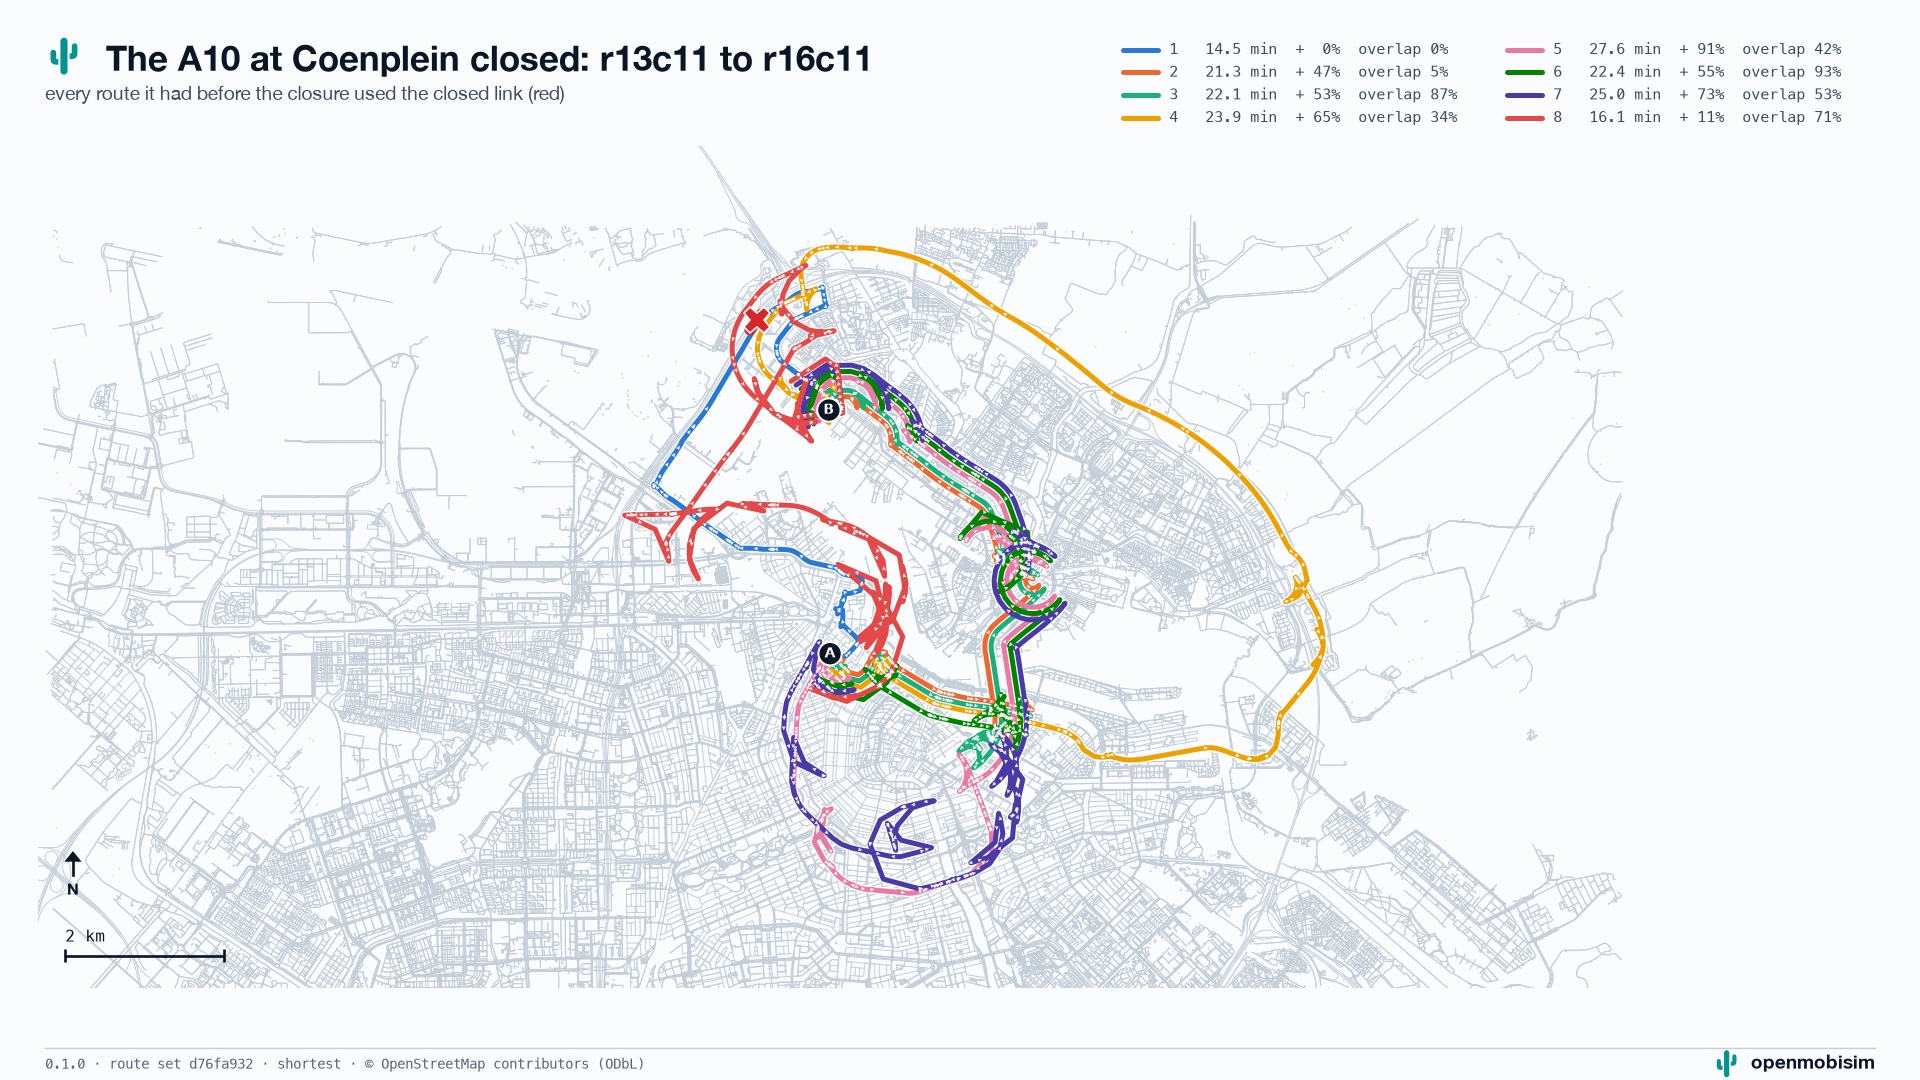

In [20]:
biggest = users[users["resident"] & (users["od"] == five[0])].groupby("pair")["weight"].sum().idxmax()
sets_after = warned.route_sets()
fig = viz.map_route(sets_after, net, pair=sets_after.find(int(origin_nodes[biggest]), int(destination_nodes[biggest])),
                    title="The A10 at Coenplein closed: " + five[0].replace(" → ", " to "),
                    subtitle="every route it had before the closure used the closed link (red)")  # fmt: skip
# The maps are drawn in metres around the mean point of the network's links: the closed link, so placed.
coords, offsets = net.link_geometry()
lon0, lat0 = coords.mean(axis=0)
line = coords[offsets[critical]:offsets[critical + 1]]
x = (line[:, 0] - lon0) * np.cos(np.radians(lat0)) * 111_320
y = (line[:, 1] - lat0) * 110_574
fig.axes[0].plot(x, y, color="#d62728", linewidth=7, solid_capstyle="round", zorder=20)
fig.axes[0].plot(x.mean(), y.mean(), marker="X", markersize=16, color="#d62728", markeredgecolor="white", zorder=21)
fig

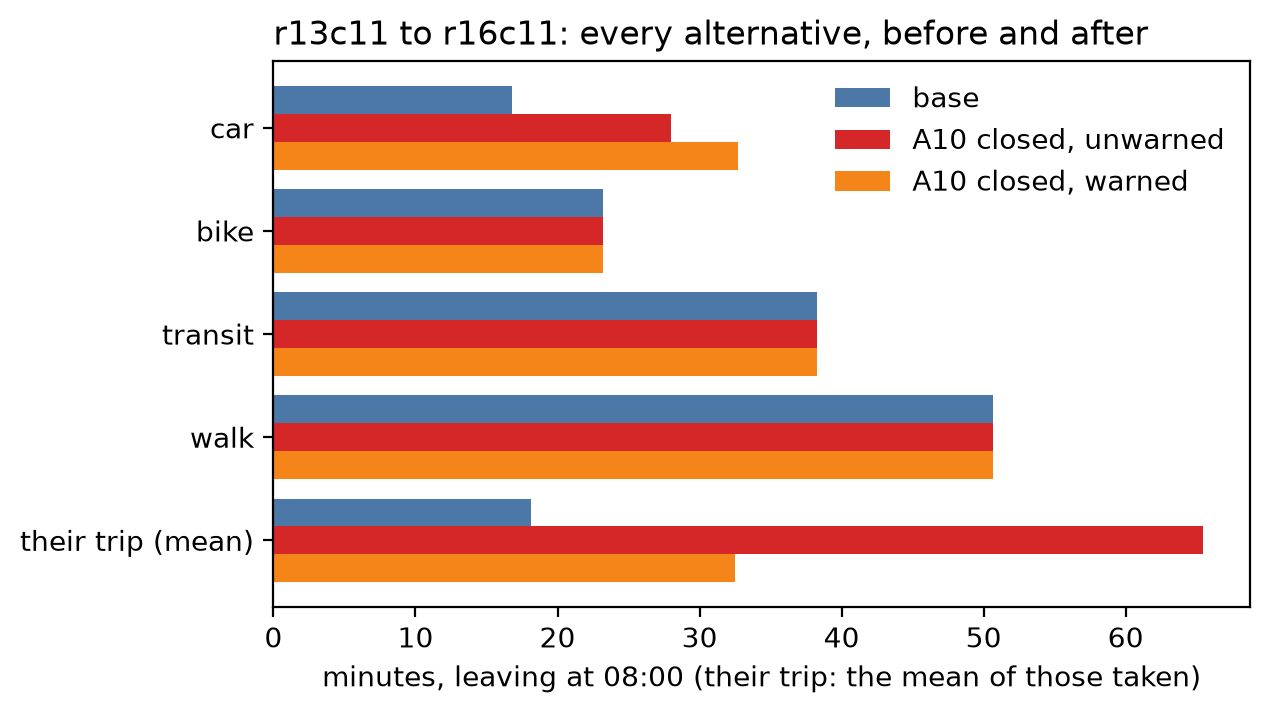

In [21]:
pair = alternatives.loc[five[0]]
fig, ax = plt.subplots(figsize=(16 / 2.54, 9 / 2.54), dpi=200)
height = 0.27
for k, (n, colour) in enumerate(zip(CLOSURE, ("#4c78a8", "#d62728", "#f58518"))):
    ax.barh(np.arange(len(pair)) + (k - 1) * height, pair[n], height=height, color=colour, label=n)  # base on top
ax.set_yticks(np.arange(len(pair)), pair.index)
ax.invert_yaxis()
ax.set_xlabel("minutes, leaving at 08:00 (their trip: the mean of those taken)")
ax.set_title(five[0].replace(" → ", " to ") + ": every alternative, before and after", loc="left")
ax.legend(frameon=False, loc="upper right")
plt.show()

**What this leaves out.** Unwarned drivers do not turn back: at the default loading (a point queue) they wait at the
closed road until it opens, so the unwarned case is an upper bound on the delay. En-route re-routing
(`loading_options={"reroute": 1}`) offers a new route only to the vehicle at the front of a queue once it has waited
`reroute_after_s`, so a long queue drains slowly that way. Nobody learns of the closure part-way through the morning (a
knowledge horizon is a later step). The importance uses free-flow detours; the runs then measure them with the
congestion they cause.

## 6 · All scenarios

The same columns for every run, the base first.

In [22]:
table(*runs)

,walk (%),bike (%),car (%),transit (%),park-and-ride (%),bike-and-ride (%),no alternative (%),mean trip (min),run time (s)
run,,,,,,,,,
base,2.13,33.77,35.31,27.81,0.13,0.37,0.48,25.44,35.26
transit twice as often,1.84,33.71,35.15,28.26,0.15,0.45,0.43,24.77,40.07
own model,1.84,33.10,36.01,28.04,0.10,0.43,0.47,25.61,33.24
"own model, transit twice as often",1.58,33.06,35.78,28.45,0.17,0.49,0.45,24.89,36.72
"A10 closed, unwarned",2.13,33.77,35.31,27.81,0.13,0.37,0.48,26.08,36.27
"A10 closed, warned",2.13,34.04,35.03,27.84,0.14,0.37,0.47,25.73,35.98


## 7 · The complete morning

Every run above was the fast one: each simulated traveller stood for five people, so each car was a block of five
on the roads and each choice made for five. Here is the **complete run**: one simulated traveller per person, every
car on its own. It is the most complete, most realistic and slowest run possible (about four times the fast run's
time), and **most applications do not need it**: compare the two below and judge for your own study.

The fast run is a small aggregation, not a different model: each group of five is a platoon of five cars, every car
counted at its full size on every link, on the network's real capacities and signals; only the group's members share
a choice and a place in the queues (notebook 02).

The **travel-time index** is the time vehicles spent on the roads over what the same traversals take at free flow
(signals' fixed waits included): 1.0 is an empty city; TomTom measures Amsterdam at 1.46 over a whole day of 2025.

In [23]:
def travel_time_index(run, start_h, end_h):
    """Road time over free-flow time, for the link traversals that ended between ``start_h`` and ``end_h``."""
    bins = run.link_bins()
    first, last = start_h * 3600 // bins.bin_seconds, end_h * 3600 // bins.bin_seconds
    keep = (bins.bins() >= first) & (bins.bins() < last)
    free = net.link_free_flow_s()[bins.links()[keep].astype(np.int64)]
    return float(bins.pcu_seconds()[keep].sum() / (bins.pcu()[keep] * free).sum())


whole = case.scenario("base", weight=1).run("complete-morning", output_dir="runs/complete-morning", quiet=True)
runs["complete morning"] = whole
indices = pd.DataFrame(
    {name: {"07-09": travel_time_index(r, 7, 9), "08-09": travel_time_index(r, 8, 9)}
     for name, r in (("fast (base)", runs["base"]), ("complete", whole))}
).T.round(2)  # fmt: skip
pd.concat([table("base", "complete morning"), indices.set_axis(["base", "complete morning"])], axis=1)

/var/folders/q0/vjghqqvj4dvcq_z2rjmvd0jmw3f5y2/T/ipykernel_63642/2734636261.py:10: NoAlternativeWarning: 1,647 trips (1,647 people, 0.6% of run 'complete-morning') had no alternative — no mode they may use reached their destination within the limits — and were not simulated. By class (stated mode): 1,445 'no_vehicle' (choosing), 176 'from_outside_transit' (transit), 26 'bike_only' (choosing). Why, by mode offered (trips): bike: ride_too_long 26; walk: walk_too_long 1,471; transit: no_stop_in_reach 1,157, no_transit_journey 490; bike_transit: no_transit_journey 21, too_short 5. Most between (latitude, longitude, about 1 km): 25 people from (52.39, 4.84) to (52.41, 4.85); 19 people from (52.39, 4.84) to (52.40, 4.85); 19 people from (52.39, 4.84) to (52.40, 4.87); 13 people from (52.38, 4.90) to (52.40, 4.87); 9 people from (52.38, 4.90) to (52.41, 4.85). To change: walk_too_long: mode_options['walk_max_s'] or the class's walk_max_s; ride_too_long: mode_options['bike_max_s'] or the class

,walk (%),bike (%),car (%),transit (%),park-and-ride (%),bike-and-ride (%),no alternative (%),mean trip (min),run time (s),07-09,08-09
base,2.13,33.77,35.31,27.81,0.13,0.37,0.48,25.44,35.26,1.44,1.58
complete morning,2.11,32.88,36.05,27.92,0.14,0.39,0.51,24.11,142.03,1.36,1.49


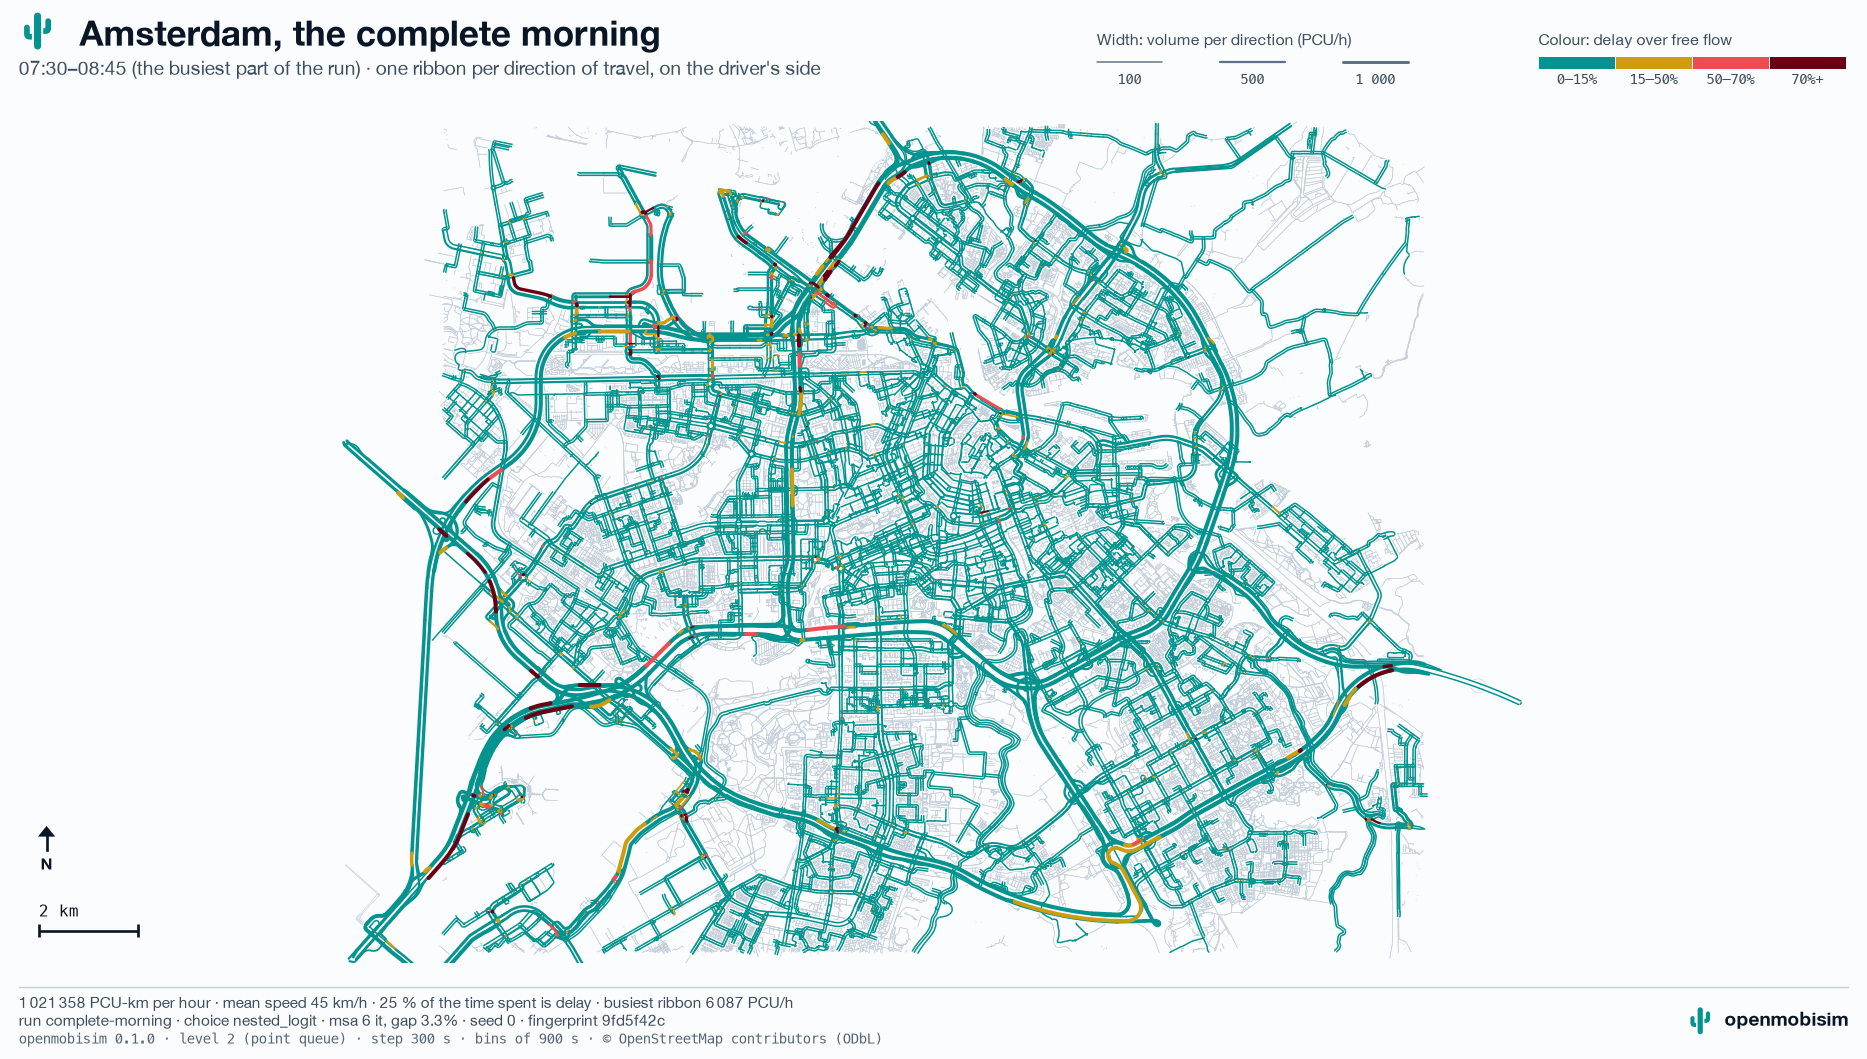

In [24]:
viz.map_link(whole, title="Amsterdam, the complete morning")

In [25]:
viz.map_interactive(whole, "runs/complete-morning/map.html", title="Amsterdam, the complete morning")

**Interactive map:** [runs/complete-morning/map.html](runs/complete-morning/map.html) — file:///private/var/folders/q0/vjghqqvj4dvcq_z2rjmvd0jmw3f5y2/T/tmp0_qq8yuh/runs/complete-morning/map.html

PosixPath('runs/complete-morning/map.html')

Every speed, coefficient, factor and share above is an uncalibrated default or an illustration; notebook 06 shows how
to change them, and each study's own data — counts, surveys, the fleet — is what turns a minimal study into a real one.

**That was the last tutorial.** Next: your own notebook, from the skeleton at the end of [00 · overview](00_getting_started.ipynb). The documentation: [openmobisim.github.io](https://openmobisim.github.io). Something wrong or unclear? [Report it](https://github.com/bahmanmdd/openmobisim/issues).